<style>
    /* Testo normale stile paper scientifico */
    body, p, li { 
        font-family: 'Georgia', 'Times New Roman', serif !important; 
        font-size: 16px !important; 
        line-height: 1.6 !important; 
        text-align: justify !important; 
    }
    /* Titoli puliti e moderni */
    h1, h2, h3, h4 { 
        font-family: 'Helvetica Neue', Arial, sans-serif !important; 
        color: #2c3e50 !important; 
        border-bottom: 1px solid #ccc; 
        padding-bottom: 5px;
    }
    /* Sfrutta meglio lo schermo durante la presentazione */
    .container { width: 85% !important; }
</style>

# Architettura Real-Time & Stream Processing: Aeroporto di Catania

Questo notebook raccoglie la documentazione, le definizioni teoriche, le specifiche architetturali e gli strumenti software del progetto per il corso di **Technologies for Advanced Programming (TAP), A.A. 2025/2026**.

<p align="center">
  <img src="images/aereo_grafico.png" alt="Aereo e grafico a barre" width="700">
</p>

## 1. Obiettivo e visione generale

Il progetto realizza una pipeline di **stream processing distribuita e disaccoppiata**, organizzata a microservizi, per il tracciamento in tempo reale dei voli in partenza e in arrivo presso l'**Aeroporto di Catania (CTA)**.

I dati vengono acquisiti in continuo dal sito dell'aeroporto, elaborati e arricchiti con una stima del rischio di ritardo, quindi indicizzati e visualizzati in una dashboard con lo scopo di:
- Monitorare in tempo reale lo stato dei voli (tabellone *Departure Board*)
- Stimare il rischio di ritardo di ciascun volo (*Basso*, *Medio*, *Alto*)
- Verificare quale compagnia aerea è la più utilizzata
- Individuare le mete più frequentate
- Calcolare il numero totale di voli

### Punti di forza e funzionalità
- **Ingestione H24 asincrona**: web scraping continuativo dal DOM dell'aeroporto, senza API proprietarie.
- **Disaccoppiamento tramite buffer in memoria**: coda FIFO ultra-veloce per prevenire la perdita di dati durante i picchi di carico.
- **Analisi predittiva della rotazione tramite LLM**: stima semantica del rischio di ritardo in base allo storico pregresso dello stesso numero di volo e della stessa rotta.
- **Indicizzazione e data visualization**: indicizzazione NoSQL time-series su Elasticsearch e visualizzazione interattiva su Grafana.

## 2. Concetti di base

Prima di entrare nel dettaglio degli strumenti, alcune definizioni utili per seguire la presentazione.

- **Stream processing**: paradigma di elaborazione in cui i dati sono trattati man mano che arrivano (flusso continuo di eventi), invece di essere accumulati ed elaborati in blocco (*batch processing*). Permette di ottenere risultati con latenza molto bassa.
- **Architettura a microservizi**: il sistema è suddiviso in componenti piccoli e indipendenti, ciascuno con una responsabilità precisa, che comunicano tra loro tramite interfacce ben definite. Ogni componente può essere sviluppato, avviato e scalato separatamente.
- **Disaccoppiamento**: i componenti non dipendono direttamente l'uno dall'altro, ma comunicano attraverso un intermediario (qui, la coda). Se un servizio rallenta o si ferma, gli altri non si bloccano.
- **Web scraping**: tecnica di estrazione automatica di informazioni da pagine web, leggendone la struttura (il **DOM**, *Document Object Model*, cioè la rappresentazione ad albero della pagina HTML).
- **Coda FIFO** (*First In, First Out*): struttura dati in cui il primo elemento inserito è anche il primo a essere estratto, garantendo il rispetto dell'ordine di arrivo.
- **Message broker**: componente che riceve messaggi dai produttori e li rende disponibili ai consumatori, gestendo la consegna in modo affidabile.
- **Serie temporale (time-series)**: sequenza di dati associati a un istante di tempo, tipicamente registrati a intervalli regolari. Qui ogni documento riporta un campo `@timestamp` in formato **ISO 8601** (ad esempio `2026-11-11T12:00:00.000Z`).
- **LLM (Large Language Model)**: modello linguistico di grandi dimensioni, addestrato su enormi quantità di testo, in grado di comprendere e generare linguaggio naturale e di classificare o sintetizzare informazioni a partire da un *prompt*.

## 3. Infrastruttura e flusso dati

<p align="center">
<img src="images/architettura_pipeline.png" alt="Infrastruttura e flusso dati" width="900">
</p>

I dati partono dal sito dell'aeroporto, attraversano la coda Redis, vengono arricchiti dal worker con lo storico di Elasticsearch e con la stima del modello Llama 3.2, e infine sono visualizzati su Grafana. I riquadri tratteggiati indicano i servizi eseguiti in container Docker.

## 4. Fasi della pipeline

1. **Data Ingestion**: scraper asincrono in Python che utilizza **Playwright** per intercettare i dati dal sito aeroportuale.
2. **Message Broker / Buffer**: coda FIFO `coda_voli_catania` gestita su **Redis** in memoria primaria.
3. **Processing & Machine Learning**: worker Python che interroga lo storico di **Elasticsearch** e invia un prompt sintetico al modello **Llama 3.2 (Ollama)**.
4. **Storage & Time-Series**: archiviazione dei documenti NoSQL con timestamp ISO 8601 (`@timestamp`) su **Elasticsearch**.
5. **Data Visualization**: dashboard **Grafana** (Departure Board con loghi delle compagnie aeree, flag emoji e indicatori KPI).

## 5. Strumenti utilizzati

### Docker & Docker Compose

<p align="center">
  <img src="images/docker.png" alt="Logo Docker" width="70">
</p>

Docker è una piattaforma di containerizzazione che impacchetta applicazioni e dipendenze in **container** isolati. Un container è un ambiente leggero che contiene tutto ciò che serve per eseguire un software (codice, librerie, configurazioni). **Docker Compose** permette di descrivere e avviare in modo coordinato più container tramite un unico file `docker-compose.yml`.

**Vantaggi principali**
- **Portabilità**: un container gira allo stesso modo su qualsiasi macchina.
- **Isolamento**: ogni componente vive nel proprio container, senza conflitti di librerie o versioni.
- **Riproducibilità**: l'infrastruttura si replica su qualsiasi macchina senza configurazioni manuali.

**Utilizzo nel progetto**
- Gestione coordinata dei container Redis, Elasticsearch, Grafana e dei tunnel di rete via `docker-compose.yml`.
- Volumi di persistenza dedicati (`es_data`, `redis_data`, `grafana_data`) che conservano i dati anche al riavvio dei container.

### Playwright (web scraping asincrono)

<p align="center">
  <img src="images/playwright.png" alt="Logo Playwright" width="50">
</p>

Playwright è una libreria moderna di automazione browser, basata sull'architettura event-driven di Chromium, che permette di controllare un browser anche in modalità **headless** (senza interfaccia grafica). A differenza dei semplici scraper basati su richieste HTTP, esegue il JavaScript della pagina e riesce quindi a leggere anche contenuti generati dinamicamente.

**Utilizzo nel progetto**
- Punto di partenza della pipeline: navigazione sul DOM del sito aeroportuale.
- Estrazione dinamica dei campi `numero_volo`, `compagnia`, `destinazione`, `stato`.
- De-duplicazione dei record prima dell'invio alla coda.

### Redis (in-memory message broker & queue)

<p align="center">
  <img src="images/redis.png" alt="Logo Redis" width="110">
</p>

Redis è un database NoSQL **in-memory** di tipo chiave-valore, noto per le prestazioni elevatissime perché mantiene i dati in RAM. Oltre a stringhe e hash supporta strutture dati come le **liste**, che possono essere usate come code di messaggi.

**Utilizzo nel progetto**
- Gestione della coda FIFO `coda_voli_catania`, che fa da buffer tra scraper e worker.
- Il produttore usa `LPUSH` per inserire i messaggi alla massima velocità.
- Il consumatore usa `BRPOP`, un'operazione **bloccante con timeout**: se la coda è vuota attende l'arrivo di un messaggio senza saturare la CPU con polling continuo. L'estrazione avviene in ordine FIFO.

### Ollama & Llama 3.2 (LLM locale)

<p align="center">
  <img src="images/ollama.png" alt="Logo Ollama" width="50">
</p>

Ollama è un framework per eseguire modelli linguistici di grandi dimensioni (LLM) su hardware locale, esponendoli tramite API. **Llama 3.2** è una famiglia di modelli linguistici open-weight sviluppata da Meta. Eseguire il modello in locale evita costi per chiamata e dipendenze da servizi esterni, e mantiene i dati all'interno dell'infrastruttura.

**Utilizzo nel progetto**
- Inferenza semantica in tempo reale per la classificazione del rischio di ritardo (*Basso*, *Medio*, *Alto*), a partire da un prompt sintetico che include lo storico della rotazione del volo.
- Configurazione con `num_ctx: 1024` (finestra di contesto ridotta) e `format: json` (output strutturato e facilmente interpretabile), per ottimizzare l'uso della RAM su CPU.

### Elasticsearch (NoSQL storage & search engine)

<p align="center">
  <img src="images/elasticsearch.png" alt="Logo Elasticsearch" width="50">
</p>

Elasticsearch è un motore di ricerca e analisi distribuito, basato su un database NoSQL orientato ai documenti (in formato JSON). Grazie all'**indicizzazione** dei campi permette query molto efficienti su grandi volumi di dati ed è particolarmente adatto a dati strutturati e serie temporali.

**Utilizzo nel progetto**
- Interrogazione dello storico per ricostruire la rotazione dei voli (stesso numero di volo e stessa rotta).
- Salvataggio finale dei documenti arricchiti nell'indice `voli_analizzati`, ciascuno con il proprio `@timestamp` in formato ISO 8601.

### Grafana (data visualization & monitoring)

<p align="center">
  <img src="images/grafana.png" alt="Logo Grafana" width="50">
</p>

Grafana è una piattaforma open source per la creazione di dashboard dinamiche e per il monitoraggio in tempo reale. Si collega a numerose sorgenti dati (tra cui Elasticsearch) e permette di costruire pannelli, tabelle, grafici e indicatori con aggiornamento automatico.

**Utilizzo nel progetto**
- Visualizzazione del tabellone voli (*Departure Board*).
- Trasformazione delle celle in immagini per mostrare i loghi delle compagnie aeree.
- Mappatura cromatica dei livelli di rischio (*Basso*, *Medio*, *Alto*).
- Aggregazione di indicatori KPI.

## 6. Simulazione ed esplorazione del dataset
Di seguito una simulazione della struttura dei documenti prodotti dalla pipeline e salvati nell'indice `voli_analizzati`.

<p align="right">
<img src="images/meme.png" alt="meme" width="300">
</p>


In [ ]:
import pandas as pd

# Simulazione della struttura dei dati processati dalla pipeline TAP
dati_voli_simulati = [
    {
        '@timestamp': '2026-11-11T12:00:00.000Z',
        'numero_volo': 'FR 06174',
        'compagnia': 'Ryanair',
        'destinazione': 'Bergamo (BGY)',
        'stato': 'In Orario',
        'rischio_ritardo': 'Basso',
        'insight': 'Rotazione regolare senza ritardi pregressi sulla rotta BGY.'
    },
    {
        '@timestamp': '2026-11-11T12:05:00.000Z',
        'numero_volo': 'W4 06507',
        'compagnia': 'Wizz Air',
        'destinazione': 'Bologna (BLQ)',
        'stato': 'Imbarco',
        'rischio_ritardo': 'Medio',
        'insight': 'La rotazione precedente ha accumulato 15m di ritardo.'
    },
    {
        '@timestamp': '2026-11-11T12:10:00.000Z',
        'numero_volo': 'AZ 01722',
        'compagnia': 'ITA Airways',
        'destinazione': 'Roma Fiumicino (FCO)',
        'stato': 'In Orario',
        'rischio_ritardo': 'Basso',
        'insight': 'Volo in orario e condizioni meteo favorevoli.'
    },
    {
        '@timestamp': '2026-11-11T12:15:00.000Z',
        'numero_volo': 'VY 06612',
        'compagnia': 'Vueling',
        'destinazione': 'Barcellona (BCN)',
        'stato': 'Ritardato',
        'rischio_ritardo': 'Alto',
        'insight': 'Congestione sulla rotta e ritardo cumulato nelle ultime 3 rotazioni.'
    }
]

df = pd.DataFrame(dati_voli_simulati)
df['@timestamp'] = pd.to_datetime(df['@timestamp'])
df

In [ ]:
df.info()
print()
print(df['rischio_ritardo'].value_counts())

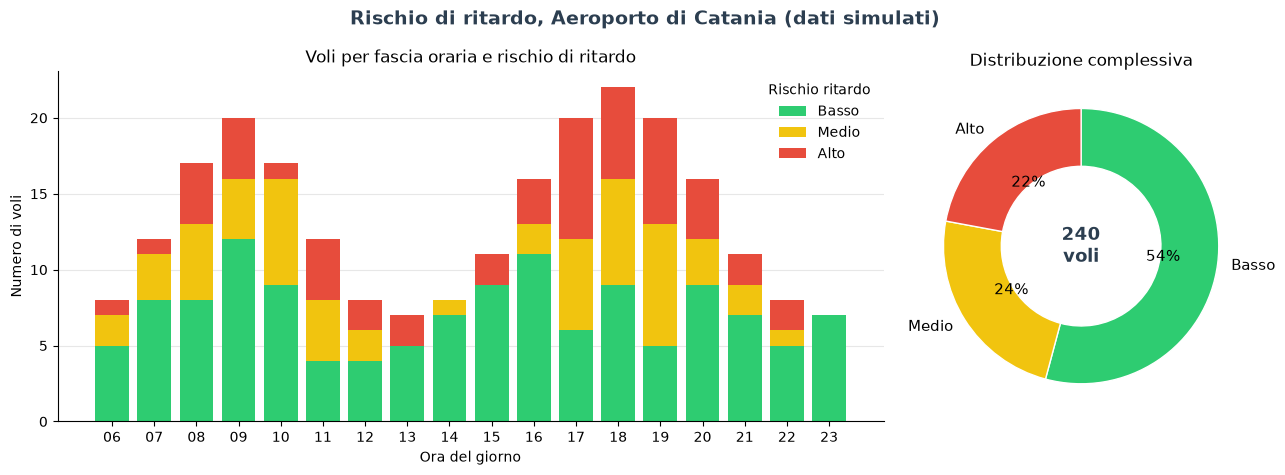

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simulazione autonoma:
# distribuzione del rischio di ritardo dei voli in partenza da CTA per fascia oraria
rng = np.random.default_rng(42)
ore = np.arange(6, 24)

# traffico simulato: picco al mattino (~9) e alla sera (~18)
traffico = (6 + 14*np.exp(-((ore-9)/2.2)**2) + 16*np.exp(-((ore-18)/2.8)**2)).round().astype(int)

# il rischio cresce con il traffico e con l'accumulo di ritardi durante la giornata
p_alto = np.clip(0.03 + 0.012*(ore-6) + 0.004*traffico, 0, 0.5)
p_medio = np.clip(0.12 + 0.006*traffico, 0, 0.4)
alto = rng.binomial(traffico, p_alto)
medio = np.minimum(rng.binomial(traffico, p_medio), traffico - alto)
basso = traffico - alto - medio

colori = {'Basso': '#2ecc71', 'Medio': '#f1c40f', 'Alto': '#e74c3c'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [2.4, 1]})

ax1.bar(ore, basso, color=colori['Basso'], label='Basso')
ax1.bar(ore, medio, bottom=basso, color=colori['Medio'], label='Medio')
ax1.bar(ore, alto, bottom=basso + medio, color=colori['Alto'], label='Alto')
ax1.set_xticks(ore)
ax1.set_xticklabels([f'{h:02d}' for h in ore])
ax1.set_xlabel('Ora del giorno')
ax1.set_ylabel('Numero di voli')
ax1.set_title('Voli per fascia oraria e rischio di ritardo', fontsize=12)
ax1.legend(title='Rischio ritardo', frameon=False)
ax1.grid(axis='y', alpha=0.3)
ax1.set_axisbelow(True)

totali = [basso.sum(), medio.sum(), alto.sum()]
ax2.pie(totali, labels=['Basso', 'Medio', 'Alto'], colors=list(colori.values()),
        autopct='%1.0f%%', startangle=90, counterclock=False,
        wedgeprops={'width': 0.42, 'edgecolor': 'white'}, textprops={'fontsize': 11})
ax2.set_title('Distribuzione complessiva', fontsize=12)
ax2.text(0, 0, f'{sum(totali)}\nvoli', ha='center', va='center', fontsize=13, fontweight='bold', color='#2c3e50')

for ax in (ax1,):
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Rischio di ritardo, Aeroporto di Catania (dati simulati)', fontsize=14, fontweight='bold', color='#2c3e50')
plt.tight_layout()
plt.show()

## 7. Snippet di codice della pipeline

### Produttore Redis (`1_scraper_produttore.py`)
<p align="right">
<img src="images/sniffing.png" alt="sniffing" width="500">
</p>



```python
import redis, json
connessione_redis = redis.Redis(host='localhost', port=6379, decode_responses=True)
# Inserimento nella coda FIFO
connessione_redis.lpush("coda_voli_catania", json.dumps(dati_volo))
```

### Consumatore & inferenza LLM (`2_consumatore_llm_elastic.py`)
```python
# Estrazione con BRPOP (bloccante con timeout) e query su Elasticsearch
risultato = connessione_redis.brpop("coda_voli_catania", timeout=5)
if risultato:
    _, raw_data = risultato
    dati_volo = json.loads(raw_data)
    # Query storica per la rotazione e classificazione LLM
```

## 8. Applicazioni pratiche

- **Pannelli informativi per i passeggeri**: stima preventiva dei ritardi e dello stato dell'imbarco.
- **Gestione operativa aeroportuale**: ottimizzazione del personale di terra in base al rischio stimato.
- **Integrazione smart city**: monitoraggio congiunto con avvisi meteo e notizie social.

## 9. Sviluppi futuri

- **Estensione multi-aeroporto**: scalabilità orizzontale su altri scali nazionali.
- **Modelli di deep learning sequenziali**: utilizzo di reti LSTM e Transformers per serie temporali complesse.
- **Deployment su Kubernetes**: orchestrazione avanzata dei microservizi in cloud.

## Bibliografia e approfondimenti

- **Docker e Docker Compose**  
  [https://docs.docker.com/compose/](https://docs.docker.com/compose/)

- **Playwright per Python**  
  [https://playwright.dev/python/](https://playwright.dev/python/)

- **Redis**  
  [https://redis.io/](https://redis.io/)

- **Ollama**  
  [https://ollama.com/](https://ollama.com/)

- **Elasticsearch**  
  [https://www.elastic.co/elasticsearch](https://www.elastic.co/elasticsearch)

- **Grafana**  
  [https://grafana.com/](https://grafana.com/)

- **Data streaming**  
  [https://aws.amazon.com/it/what-is/streaming-data](https://aws.amazon.com/it/what-is/streaming-data)

- **ISO 8601 (formato dei timestamp)**  
  [https://en.wikipedia.org/wiki/ISO_8601](https://en.wikipedia.org/wiki/ISO_8601)